In [15]:
from mlxtend.plotting import plot_decision_regions

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#                                               Thoery
```js
        All the theories for Decision Tree classification is in "Decision Tree Classification.pdf" in Theory folder.
```

#                                       Playing with "max_depth" paramater

For max_depth = None, accuracy = 0.85.
For max_depth = 1, accuracy = 0.85.
For max_depth = 3, accuracy = 0.8875.
For max_depth = 10, accuracy = 0.8625.


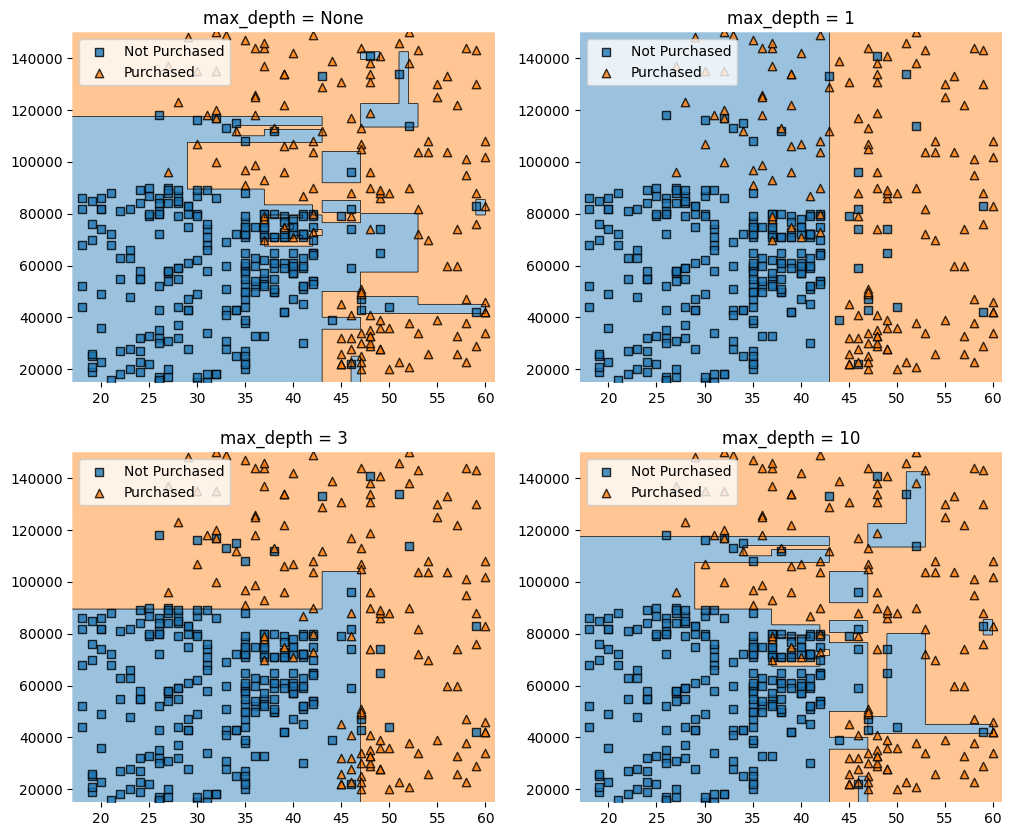

In [40]:
df = pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\6. Decision Tree\Dataset\Social_Network_Ads.csv")
X = df.iloc[:, [2, 3]].values  # [Age, EstimatedSalary].
y = df.iloc[:, -1].values      # [Purchased].

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

def model_with_newDepth(maxDepth):
    clf = DecisionTreeClassifier(max_depth = maxDepth).fit(X = x_train, y = y_train)
    print(f"For max_depth = {maxDepth}, accuracy = {accuracy_score(y_true = y_test, y_pred = clf.predict(x_test))}.")
    return clf

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax1 = plot_decision_regions(X = X, y = y, clf = model_with_newDepth(None), ax = axes[0, 0])
ax1.legend(['Not Purchased', "Purchased"])
ax1.set_title("max_depth = None")

ax2 = plot_decision_regions(X = X, y = y, clf = model_with_newDepth(1), ax = axes[0, 1])
ax2.legend(['Not Purchased', "Purchased"])
ax2.set_title("max_depth = 1")

ax3 = plot_decision_regions(X = X, y = y, clf = model_with_newDepth(3), ax = axes[1, 0])
ax3.legend(['Not Purchased', "Purchased"])
ax3.set_title("max_depth = 3")

ax4 = plot_decision_regions(X = X, y = y, clf = model_with_newDepth(10), ax = axes[1, 1])
ax4.legend(['Not Purchased', "Purchased"])
ax4.set_title("max_depth = 10")

explanation = """
Decision Tree doesn't return line|lines to classify data. In the first graph we can see that the Decision Tree classified the
Blue region as Yes|"Purchased" and the other region as No|"Not Purchased". Similarly for the rest graphs.
"""

#                                   Plotting Decision Tree 1

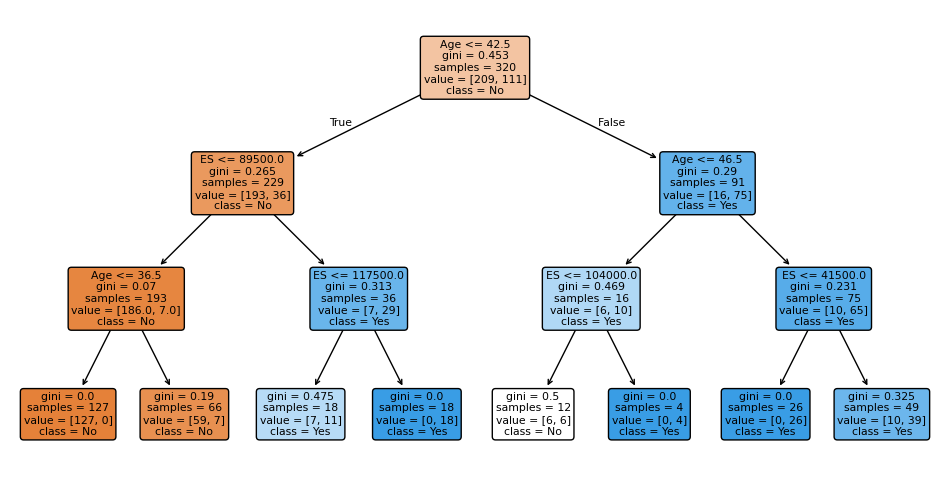

In [ ]:
from sklearn.tree import plot_tree

df = pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\6. Decision Tree\Dataset\Social_Network_Ads.csv")

X = df.iloc[:, [2, 3]]  # [Age, EstimatedSalary].
y = df.iloc[:, -1]      # [Purchased].

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

dt = DecisionTreeClassifier(max_depth = 3).fit(X = x_train, y = y_train)

plt.figure(figsize=(12, 6))
plot_tree(decision_tree = dt, # plot_tree() worked for me after installing graphviz.
          feature_names = ['Age', 'ES'], # feature_names = Input column names.
          class_names = ['No', 'Yes'],   # [0, 1].
          filled = True, # colors the nodes.
          rounded = True) # draw node boxes with rounded corners and use Helvetica fonts instead of Times-Roman.
plt.show()

explanation_of_tree = """
samples = Number of rows of the new dataset after splitting on that node.

[ y, output column, has 2 unique values -> 0 (no) and 1 (yes). ]
value = [no_of_rows_has_the_output_0_in_CURRENT_NODE, no_of_rows_has_the_output_1_in_CURRENT_NODE].
E.G., The left node of root node has samples = 229 i.e. 229 rows given in the left node after the split in the root node.
      value = [193, 36] means out of 229 rows 193 rows has the output 0(didn't purchase) and 36 rows has 1(purchased).

class = The output of the node. E.g., for the root node class = No. That means if Age <= 42.5, user won't purchase.
"""

#                                   Plotting Decision Tree 2

In [ ]:
import dtreeviz

df = pd.read_csv(r"D:\VS CODE\Data Science\Machine Learning\6. Decision Tree\Dataset\Social_Network_Ads.csv")

X = df.iloc[:, [2, 3]].values  # [Age, EstimatedSalary].
y = df.iloc[:, -1].values      # [Purchased].

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)

dt = DecisionTreeClassifier(max_depth = 3).fit(X = x_train, y = y_train)

viz_model = dtreeviz.model(model = dt,
                           X_train = x_train, y_train = y_train, # must be numpy array.
                           feature_names = ['Age', 'ES'],
                           target_name = 'Purchased')

viz_model.view() # Tried every way, but couldn't get it work.

ExecutableNotFound: failed to execute 'dot', make sure the Graphviz executables are on your systems' PATH